## Importações

In [1]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"  # antes do numpy: evita falta de memória do OpenBLAS no Windows

import pandas as pd
import seaborn as sns

## Carregamento da base original

In [2]:
cols = ["SD_front", "SD_left", "SD_right", "SD_back", "Class"]
atributos = cols[:-1]
df = pd.read_csv("wall+following+robot+navigation+data/sensor_readings_4.data", header=None, names=cols)
print("Instâncias:", len(df))

Instâncias: 5456


## Verificação de valores ausentes e duplicados

In [3]:
print("Valores ausentes:", df.isna().sum().sum())
print("Linhas duplicadas:", df.duplicated().sum())
print("Atributos iguais com classes diferentes:", (df.groupby(atributos)["Class"].nunique() > 1).sum())

Valores ausentes: 0
Linhas duplicadas: 50
Atributos iguais com classes diferentes: 0


## Remoção das linhas duplicadas

In [4]:
df = df.drop_duplicates(ignore_index=True)
print("Instâncias após remoção:", len(df))

Instâncias após remoção: 5406


## Normalização z-score
Outliers e leituras saturadas em 5,0 m (alcance máximo do sensor) são mantidos: são medições reais.

In [5]:
df[atributos] = (df[atributos] - df[atributos].mean()) / df[atributos].std()
display(df[atributos].agg(["mean", "std"]).round(4))

,SD_front,SD_left,SD_right,SD_back
mean,0.0,0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0


## Salvar base processada

In [6]:
df.to_csv("wall+following+robot+navigation+data/sensor_readings_4_processed.csv", index=False)

# Análise de dados da base processada

## Número de classes e número de instâncias por classe.

Número de classes: 4
Total de instâncias: 5406

                   Instâncias      %
Class                               
Move-Forward             2202  40.73
Sharp-Right-Turn         2083  38.53
Slight-Right-Turn         793  14.67
Slight-Left-Turn          328   6.07


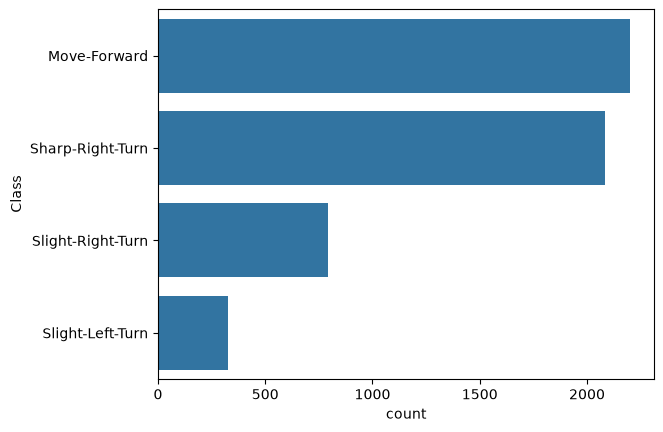

In [7]:
contagem = df["Class"].value_counts()
print(f"Número de classes: {df['Class'].nunique()}")
print(f"Total de instâncias: {len(df)}\n")
print(pd.DataFrame({"Instâncias": contagem, "%": (contagem / len(df) * 100).round(2)}))

sns.countplot(data=df, y="Class", order=contagem.index);

## Valor médio, variância, assimetria e curtose dos atributos por classe.

In [8]:
stats = df.groupby("Class").agg(["mean", "var", "skew", "kurt"])

nomes = {"mean": "Valor médio", "var": "Variância", "skew": "Assimetria", "kurt": "Curtose (excesso)"}
for stat, nome in nomes.items():
    print(f"\n{nome}")
    display(stats.xs(stat, axis=1, level=1).round(4))


Valor médio


,SD_front,SD_left,SD_right,SD_back
Class,,,,
Move-Forward,0.4745,-0.0898,-0.0319,-0.2360
Sharp-Right-Turn,-0.7828,-0.0555,0.0539,0.1905
Slight-Left-Turn,0.2699,2.5620,-0.4413,1.0711
Slight-Right-Turn,0.6268,-0.6645,0.1294,-0.2883



Variância


,SD_front,SD_left,SD_right,SD_back
Class,,,,
Move-Forward,1.1900,0.0761,0.8928,0.5074
Sharp-Right-Turn,0.0138,0.9299,1.4134,1.6534
Slight-Left-Turn,0.2705,2.3362,0.3103,0.3070
Slight-Right-Turn,0.7084,0.0131,0.3917,0.1327



Assimetria


,SD_front,SD_left,SD_right,SD_back
Class,,,,
Move-Forward,1.4410,0.1700,1.1658,3.3174
Sharp-Right-Turn,-1.8187,7.7536,0.6665,1.9345
Slight-Left-Turn,0.0562,1.5785,0.5138,1.8763
Slight-Right-Turn,2.2204,-1.5242,2.0517,-0.2948



Curtose (excesso)


,SD_front,SD_left,SD_right,SD_back
Class,,,,
Move-Forward,1.7841,-0.9398,0.7060,17.1633
Sharp-Right-Turn,4.0536,78.7494,-0.5175,3.2764
Slight-Left-Turn,-1.2854,5.0184,0.3170,10.4767
Slight-Right-Turn,8.7038,1.3930,8.1238,-0.1663


## Histogramas dos atributos (aproximação da densidade marginal de cada atributo)

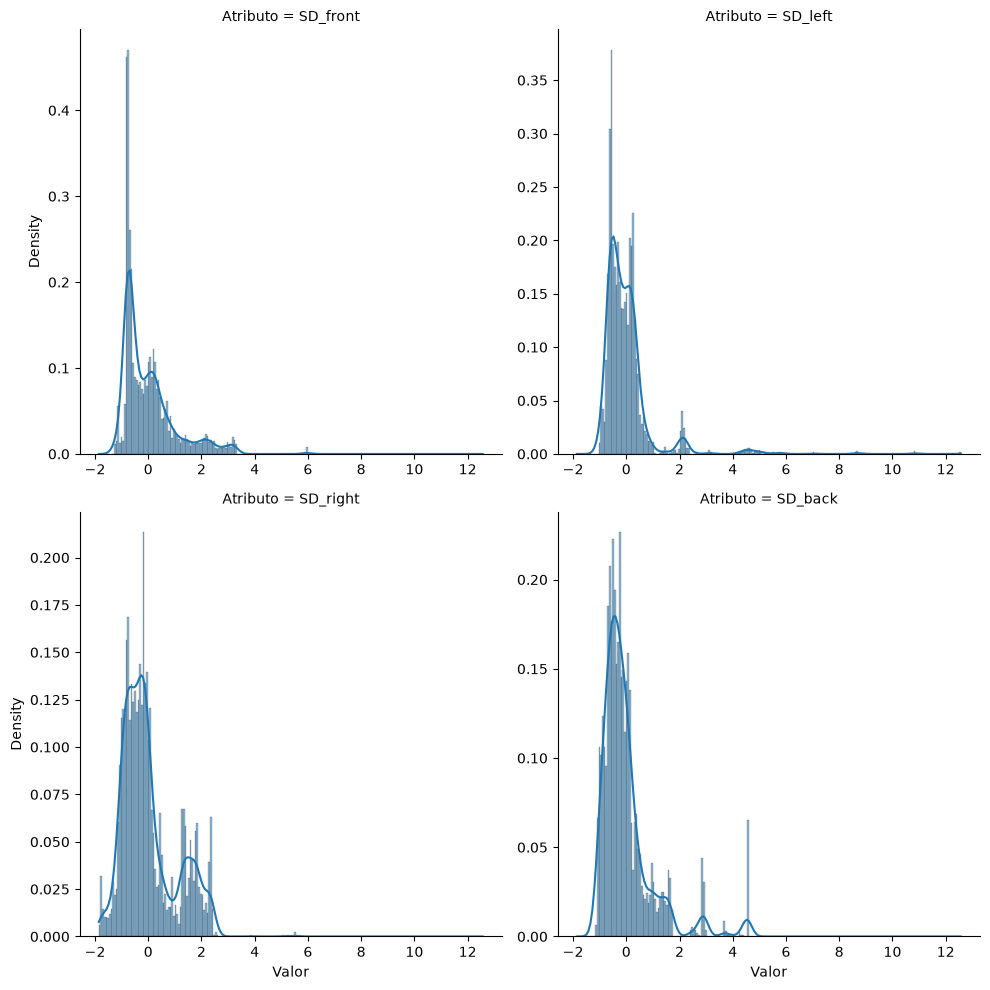

In [9]:
longo = df.melt(id_vars="Class", var_name="Atributo", value_name="Valor")

sns.displot(
    longo, x="Valor", col="Atributo", col_wrap=2,
    stat="density", kde=True,
    facet_kws={"sharex": False, "sharey": False},
);

## Scatterplot map com todas as combinações de pares de variáveis de entrada

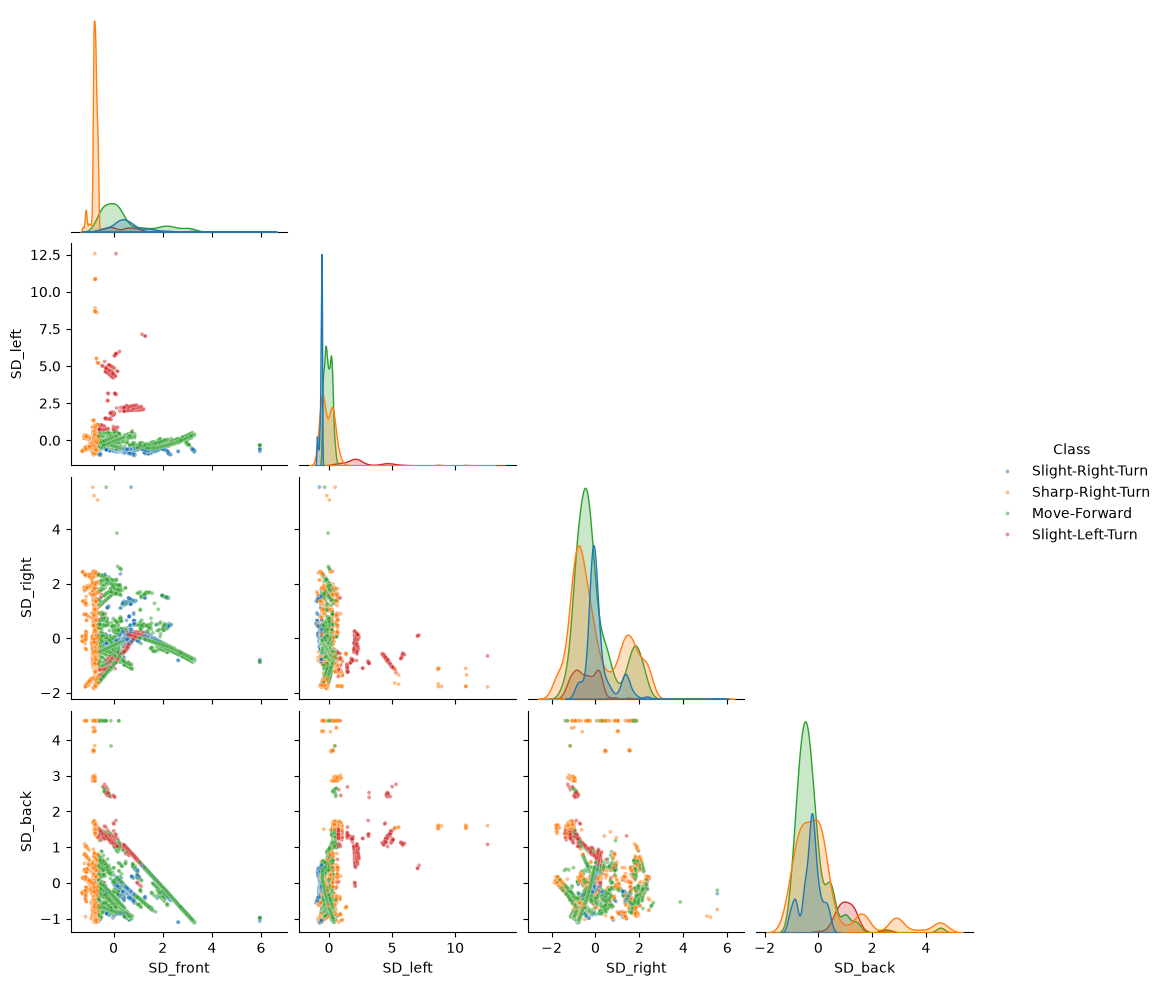

In [10]:
sns.pairplot(df, hue="Class", corner=True, plot_kws={"s": 8, "alpha": 0.5});

## Calcular a matriz de correlação dos atributos

,SD_front,SD_left,SD_right,SD_back
SD_front,1.0000,-0.0254,-0.1006,-0.2148
SD_left,-0.0254,1.0000,-0.2034,0.3326
SD_right,-0.1006,-0.2034,1.0000,-0.0389
SD_back,-0.2148,0.3326,-0.0389,1.0000


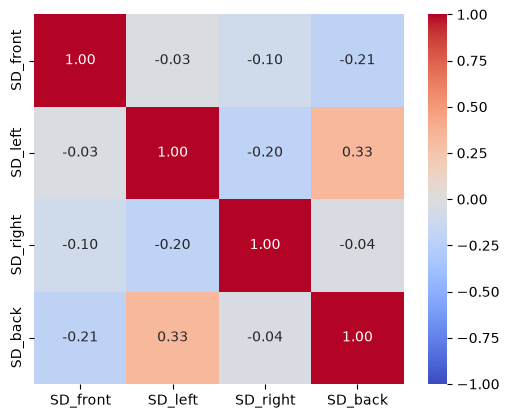

In [11]:
corr = df[atributos].corr()
display(corr.round(4))

sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True);